# 07 · Hierarchical reconciliation — store totals must match state and national totals
Item-store forecasts from LightGBM do **not** add up to forecasts made for a store, a state or the total. Managers
need one coherent set of numbers. We:
1. forecast every level (bottom = LightGBM, stores/states/total = Holt-Winters on the aggregated series),
2. reconcile with **MinT (weighted least squares, structural weights)** so that all levels add up,
3. check accuracy per level and verify coherence numerically.

Hierarchy: **total → state → store → item-store**.

In [1]:
import sys; sys.path.insert(0, "..")
import warnings, logging; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from src.config import *
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from src.reconcile import build_hierarchy, mint_reconcile, bottom_up, coherence_gap
from src.metrics import wape
feat = pd.read_parquet(PROC_DIR / "features.parquet", columns=["id", "date", "sales", "store_id", "state_id"])
pt = pd.read_parquet(OUT_DIR / "pred_point.parquet")[["id", "date", "sales", "pred_lgbm"]]
test_dates = sorted(pt.date.unique())
meta = feat[["id", "store_id", "state_id"]].drop_duplicates("id")
names, S, bottom = build_hierarchy(meta)
print(f"{len(names)} series in the hierarchy; summing matrix {S.shape}")

610 series in the hierarchy; summing matrix (610, 600)


## Base forecasts for every level

In [2]:
hist = feat[feat.date < test_dates[0]].pivot(index="date", columns="id", values="sales")[bottom]   # T x n_bottom
Y_hist_all = (S @ hist.values.T)                                      # n_all x T  (aggregated history)
n_upper = S.shape[0] - len(bottom)
base_bottom = pt.pivot(index="id", columns="date", values="pred_lgbm").loc[bottom].values        # n_bottom x 28
actual_bottom = pt.pivot(index="id", columns="date", values="sales").loc[bottom].values
actual_all = S @ actual_bottom

base_upper = np.zeros((n_upper, len(test_dates)))
for i in range(n_upper):
    y = Y_hist_all[i] + 1e-3
    fit = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7).fit()
    base_upper[i] = np.clip(fit.forecast(len(test_dates)), 0, None)
base_all = np.vstack([base_upper, base_bottom])
print("coherence gap BEFORE reconciliation (units):", round(coherence_gap(base_all, S), 1))

coherence gap BEFORE reconciliation (units): 147.9


## Reconcile: MinT (wls_struct) vs simple bottom-up

In [3]:
rec_mint = np.clip(mint_reconcile(base_all, S), 0, None)
rec_bu = bottom_up(base_bottom, S)
print("coherence gap AFTER MinT:", f"{coherence_gap(mint_reconcile(base_all, S), S):.2e}")

level = np.array(["total"] * 1 + ["state"] * 3 + ["store"] * (S.shape[0] - len(bottom) - 4) + ["item-store"] * len(bottom))
rows = []
for lv in ["total", "state", "store", "item-store"]:
    m = level == lv
    for name, F in [("base (unreconciled)", base_all), ("bottom-up", rec_bu), ("MinT reconciled", rec_mint)]:
        rows.append(dict(level=lv, method=name, n_series=int(m.sum()), WAPE=wape(actual_all[m], F[m])))
lvl = pd.DataFrame(rows).pivot(index="level", columns="method", values="WAPE").loc[["total", "state", "store", "item-store"]]
lvl = lvl.round(4); lvl.to_csv(OUT_DIR / "metrics_reconciliation.csv"); lvl

coherence gap AFTER MinT: 0.00e+00


method,MinT reconciled,base (unreconciled),bottom-up
level,,,
total,0.0518,0.0745,0.0419
state,0.0647,0.0777,0.0546
store,0.0865,0.0963,0.0789
item-store,0.6801,0.6699,0.6699


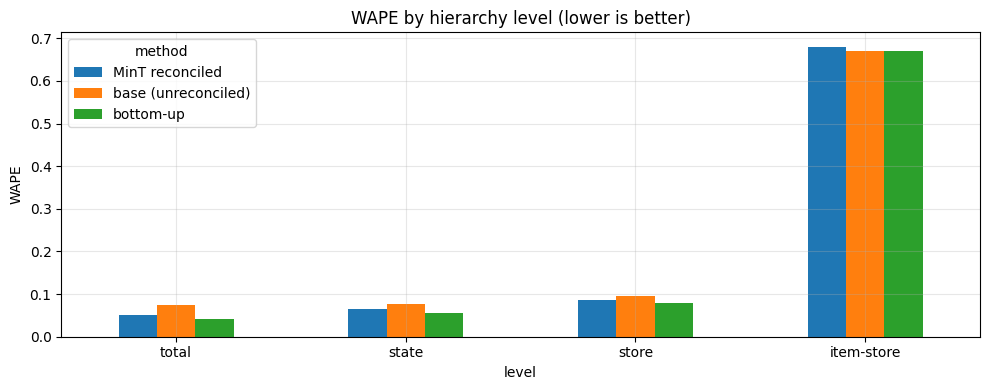

In [4]:
lvl.plot.bar(title="WAPE by hierarchy level (lower is better)"); plt.ylabel("WAPE"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "07_reconciliation.png", dpi=120); plt.show()

## Save reconciled item-store forecasts and prove coherence on the real numbers

In [5]:
rb = rec_mint[-len(bottom):]
out = pd.DataFrame(rb, index=bottom, columns=test_dates).stack().rename("pred_reconciled").reset_index()
out.columns = ["id", "date", "pred_reconciled"]
pd.read_parquet(OUT_DIR / "pred_point.parquet").merge(out, on=["id", "date"]).to_parquet(OUT_DIR / "pred_point.parquet")
store_idx = [i for i, n in enumerate(names) if n.startswith("store:")]
state_idx = [i for i, n in enumerate(names) if n.startswith("state:")]
sums_ok = np.allclose(rec_mint[store_idx].sum(axis=0) , rec_mint[state_idx].sum(axis=0)) and           np.allclose(rec_mint[state_idx].sum(axis=0), rec_mint[0])
print("Store totals sum to state totals sum to national total on every day:", sums_ok)
assert sums_ok

Store totals sum to state totals sum to national total on every day: True


**Talking point:** reconciliation usually helps the aggregate levels the most and leaves item-store accuracy roughly
unchanged — but the real win is *coherent* plans: warehouse, regional and store orders finally agree.